Responsible AI: Student Performance Prediction & Fairness Analysis

Project Objective

The objective of this project is to develop a machine learning model to predict student performance and analyze its fairness, bias, and explainability using SHAP.

This project demonstrates the principles of Responsible AI by examining feature importance, interpreting model predictions, and identifying potential bias across student groups.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("../data/student-mat.csv", sep=";")

# Display the first five rows
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
# Dataset shape
print("Dataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

# Dataset information
df.info()

Dataset shape: (395, 33)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing values:
0
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    

Exploratory Data Analysis (EDA)

In this section, we explore the student dataset to understand the distribution of student grades and identify relationships between different features and academic performance.

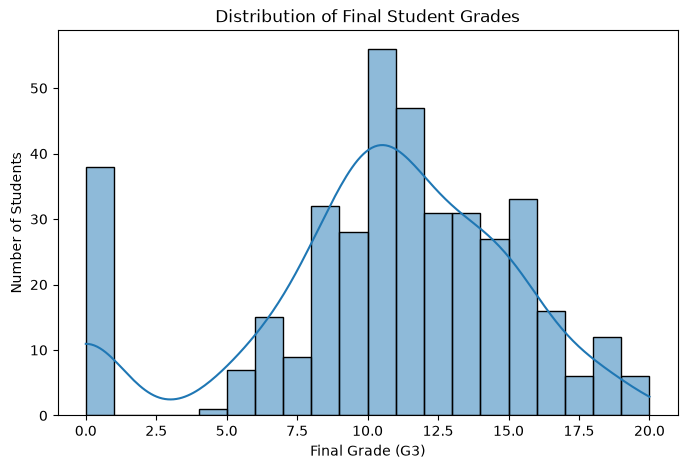

In [3]:
# Distribution of final grades
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=20, kde=True)

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


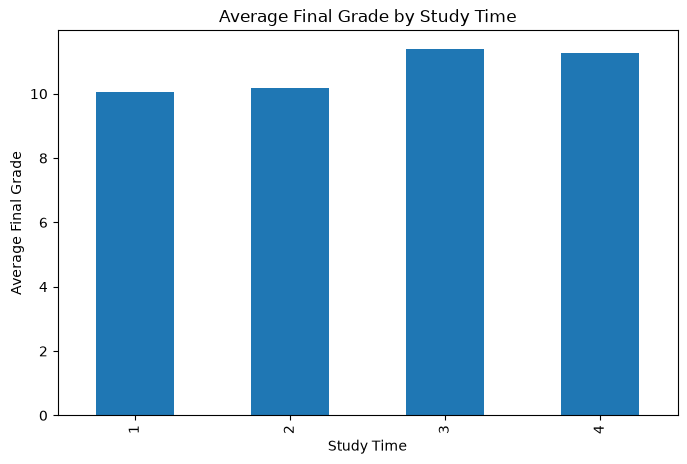

In [4]:
# Average final grade based on study time
study_grade = df.groupby("studytime")["G3"].mean()

print(study_grade)

study_grade.plot(kind="bar", figsize=(8, 5))

plt.title("Average Final Grade by Study Time")
plt.xlabel("Study Time")
plt.ylabel("Average Final Grade")

plt.show()

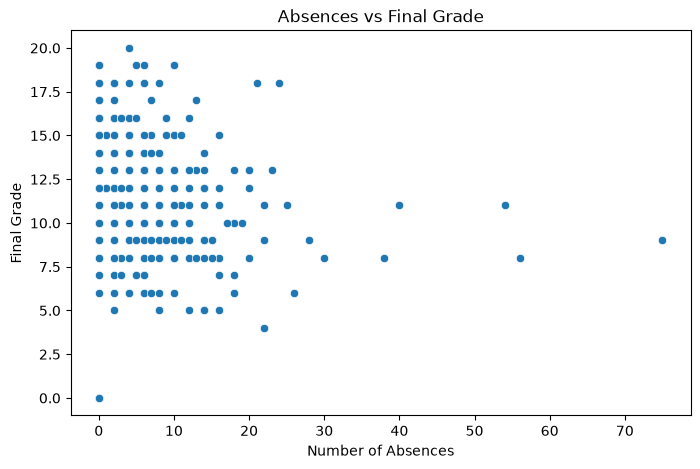

In [5]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="absences", y="G3")

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.show()

Machine Learning Model Development

In this section, we develop a Random Forest classification model to predict student pass or fail outcomes. The model will be evaluated using accuracy, precision, recall, and F1-score.

The prediction target is based on the student's final grade (G3), where a grade of 10 or higher is considered a pass.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create target variable
# 1 = Pass, 0 = Fail
df["pass"] = (df["G3"] >= 10).astype(int)

# Remove G3 to prevent data leakage
X = df.drop(columns=["G3", "pass"])

# Target variable
y = df["pass"]

# Convert categorical variables into numerical variables
X = pd.get_dummies(X, drop_first=True)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create the Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8607594936708861

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.92      0.81        26
           1       0.96      0.83      0.89        53

    accuracy                           0.86        79
   macro avg       0.84      0.88      0.85        79
weighted avg       0.88      0.86      0.86        79


Confusion Matrix:
[[24  2]
 [ 9 44]]


Feature Importance Analysis

Feature importance helps identify which input variables contribute most to the model's predictions.

In this project, we use the feature importance values from the Random Forest model to understand the factors influencing student pass/fail predictions.

In [7]:
# Calculate feature importance
importance = model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print(feature_importance.head(15))

          Feature  Importance
14             G2    0.386750
13             G1    0.212179
5        failures    0.042275
12       absences    0.036179
8           goout    0.022061
10           Walc    0.018652
0             age    0.018526
11         health    0.017883
7        freetime    0.015491
4       studytime    0.014731
3      traveltime    0.013928
6          famrel    0.013819
33  schoolsup_yes    0.012911
2            Fedu    0.012412
1            Medu    0.012184


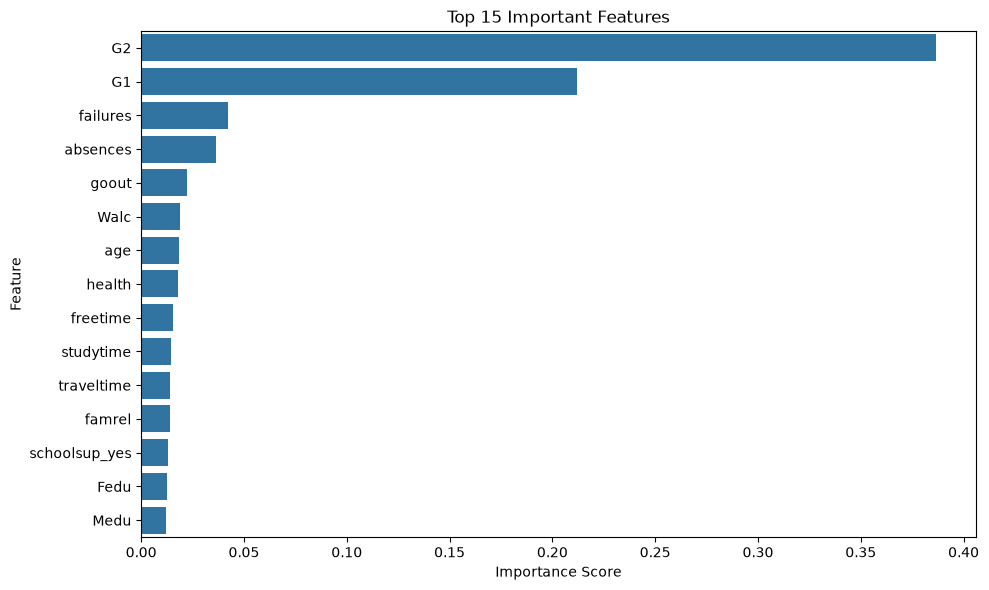

In [8]:
# Plot top 15 important features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()